<a href="https://colab.research.google.com/github/BlackTaias/Sistema-Especialista-Overwatch-Projeto/blob/main/SE_Partida_de_Overwatch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **SISTEMA ESPECIALISTA SOBRE DESEMPENHO DE EQUIPE NO OVERWATCH**
# **Objetivo Principal**: O Objetivo do Projeto foi criar um Sistema Especialista para o Desempenho das Equipes antes de uma Partida Do Overwatch começar, ele vai analisar o desempenho do mapa, do Tank, do DPS e do Suporte, calcular os pontos de todo o desempenho e comparar entre as duas equipes, quem tem a maior vantagem de vitória.

# **Descrição**: Um Sistema Especialista para avaliar equipes de Overwatch e determinar se a equipe está equilibrada. Utilizando a base de conhecimentos SE... ENTÃO e seu motor de inferência Foward Chaining, sua base de fatos vem das informações fornecidas pelo usuário querendo saber se sua equipe tem chances de vitória com base do desempenho, sinergia e precisão na jogabilidade dos seus companheiros de equipe com base da pontuação de habilidade do jogador.

# **Base e Conhecimento de Regras**: SE... ENTÃO, com as 4 regras
# R1: SE a Equipe 1 tiver vantagem de 10 pontos ou mais, ENTÃO, indicar vantagem ampla para equipe 1
# R2: SE a Equipe 2 tiver vantagem de 10 pontos ou mais, ENTÃO, indicar vantagem para a equipe 2
# R3: SE a diferença entre as equipes for maior que 5 e menor que 10, ENTÃO, indicar pequena vantagem competitiva
# R4: SE ambas as equipes for menor ou igual a 5, ENTÃO, classificar a partida como equilibrada.

# **Motor de Inferência**: Seu motor de Inferência é o Foward Chaining, ele vai juntar todas as pontuações marcadas por ambas as equipes e deduzir quem está com a maior vantagem ou se a partida será equilibrada, utilizando as regras R1 até a R4.

In [ ]:
# importação das bibliotecas necessárias
# pandas: manipulação e análise de dados estruturados
import pandas as pd
# matplotlib.pyplot: geração de gráficos e visualizações
import matplotlib.pyplot as plt
# train_test_split: divisão do dataset em conjuntos de treino e teste
from sklearn.model_selection import train_test_split
# DecisionTreeClassifier: o algoritmo de árvore de decisão para classificação
# export_text e plot_tree: ferramentas para visualizar as regras aprendidas pela árvore
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
# Métricas para avaliação do modelo: acurácia e matriz de confusão
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Confirmação de que as dependências foram carregadas com sucesso
print("Bibliotecas carregadas.")

Bibliotecas carregadas.


=== SISTEMA ESPECIALISTA OVERWATCH 2 ===

Nome da primeira equipe: Os Melhores

Informe as notas da equipe (0 a 100):
Desempenho do Tank: -10
ERRO: Digite uma nota entre 0 e 100.
Desempenho do Tank: 0
Desempenho do DPS: 50
Desempenho do Suporte: 85
Sinergia da equipe: 100
Adaptação ao mapa: 100

Nome da segunda equipe: Os Piores

Informe as notas da equipe (0 a 100):
Desempenho do Tank: 101
Desempenho do DPS: 120
Desempenho do Suporte: 50
Sinergia da equipe: 100
Adaptação ao mapa: 65

=== DESEMPENHO DAS EQUIPES ===
     Equipe  Tank   DPS  Suporte  Sinergia  Mapa  Pontuação
Os Melhores   0.0  50.0     85.0     100.0 100.0      64.50
  Os Piores 101.0 120.0     50.0     100.0  65.0      89.95

=== DIAGNÓSTICO DO SISTEMA ===
Equipe com vantagem: Os Piores
Prognóstico: Vitória provável.


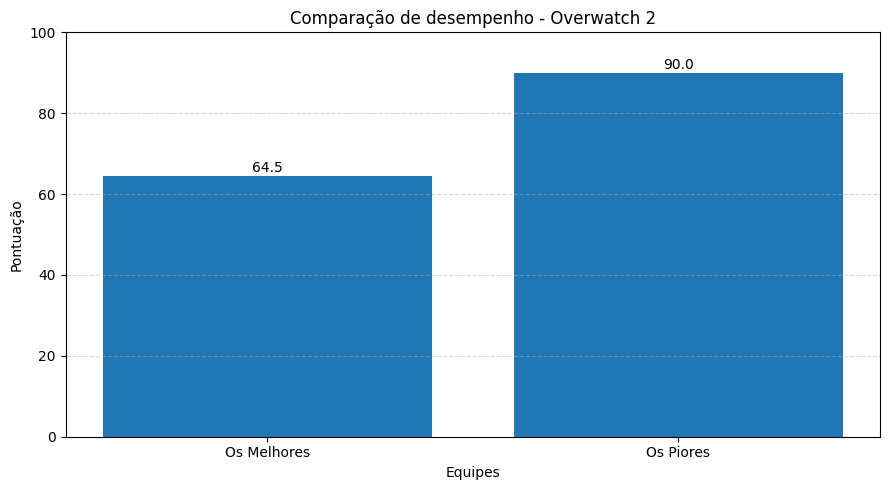


Análise finalizada pelo sistema especialista!


In [ ]:
# ==========================================
# FUNÇÃO PARA VALIDAR AS NOTAS
# ==========================================

def receber_nota(criterio):

    while True:
        try:
            nota = float(input(f"{criterio}: "))

            if 0 <= nota <= 100:
                return nota

            print("ERRO: Digite uma nota entre 0 e 100.")

        except ValueError:
            print("ERRO: Digite um número válido.")
# ==========================================
# SISTEMA ESPECIALISTA - OVERWATCH 2
# Análise de chances de vitória de uma equipe
# ==========================================
# ------------------------------------------
# 1. Entrada de dados das equipes
# ------------------------------------------

print("=== SISTEMA ESPECIALISTA OVERWATCH 2 ===")

# Dados da primeira equipe
equipe1 = input("\nNome da primeira equipe: ")

print("\nInforme as notas da equipe (0 a 100):")

tank1 = receber_nota("Desempenho do Tank")
dps1 = float(input("Desempenho do DPS: "))
suporte1 = float(input("Desempenho do Suporte: "))
sinergia1 = float(input("Sinergia da equipe: "))
mapa1 = float(input("Adaptação ao mapa: "))

# Dados da segunda equipe
equipe2 = input("\nNome da segunda equipe: ")

print("\nInforme as notas da equipe (0 a 100):")

tank2 = float(input("Desempenho do Tank: "))
dps2 = float(input("Desempenho do DPS: "))
suporte2 = float(input("Desempenho do Suporte: "))
sinergia2 = float(input("Sinergia da equipe: "))
mapa2 = float(input("Adaptação ao mapa: "))

# ------------------------------------------
# 2. Organização dos dados com Pandas
# ------------------------------------------

dados = {
    "Equipe": [equipe1, equipe2],
    "Tank": [tank1, tank2],
    "DPS": [dps1, dps2],
    "Suporte": [suporte1, suporte2],
    "Sinergia": [sinergia1, sinergia2],
    "Mapa": [mapa1, mapa2]
}

# Criação do DataFrame
df = pd.DataFrame(dados)

# ------------------------------------------
# 3. Base de conhecimento
# Definição dos pesos de cada critério
# ------------------------------------------

pesos = {
    "Tank": 0.20,
    "DPS": 0.25,
    "Suporte": 0.20,
    "Sinergia": 0.20,
    "Mapa": 0.15
}

# ------------------------------------------
# 4. Motor de inferência
# Cálculo da pontuação das equipes
# ------------------------------------------

df["Pontuação"] = (
    df["Tank"] * pesos["Tank"] +
    df["DPS"] * pesos["DPS"] +
    df["Suporte"] * pesos["Suporte"] +
    df["Sinergia"] * pesos["Sinergia"] +
    df["Mapa"] * pesos["Mapa"]
)

# ------------------------------------------
# 5. Apresentação dos resultados
# ------------------------------------------

print("\n=== DESEMPENHO DAS EQUIPES ===")

print(df.to_string(index=False))

# Comparação das pontuações
diferenca = abs(df.loc[0, "Pontuação"] -
                df.loc[1, "Pontuação"])

print("\n=== DIAGNÓSTICO DO SISTEMA ===")

# ------------------------------------------
# 6. Regras de decisão
# ------------------------------------------

if diferenca >= 10:

    vencedor = df.loc[
        df["Pontuação"].idxmax(), "Equipe"
    ]

    print("Equipe com vantagem:", vencedor)
    print("Prognóstico: Vitória provável.")

elif diferenca <= 5:

    print("Prognóstico: Partida equilibrada.")
    print("As equipes possuem pontuações próximas.")

else:

    print("Prognóstico: Existe uma pequena vantagem")
    print("para uma das equipes.")

# ------------------------------------------
# 7. Gráfico comparativo com Matplotlib
# ------------------------------------------

plt.figure(figsize=(9, 5))

plt.bar(
    df["Equipe"],
    df["Pontuação"]
)

plt.title("Comparação de desempenho - Overwatch 2")
plt.xlabel("Equipes")
plt.ylabel("Pontuação")

plt.ylim(0, 100)

plt.grid(axis="y", linestyle="--", alpha=0.5)

# Exibição dos valores acima das barras
for i, valor in enumerate(df["Pontuação"]):
    plt.text(i, valor + 1, f"{valor:.1f}",
             ha="center")

plt.tight_layout()
plt.show()

# ------------------------------------------
# 8. Finalização
# ------------------------------------------

print("\nAnálise finalizada pelo sistema especialista!")


In [ ]:

# ==========================================
# MOTOR DE INFERÊNCIA - FORWARD CHAINING
# ==========================================

# 1. Base de fatos iniciais

pontuacao1 = df.loc[0, "Pontuação"]
pontuacao2 = df.loc[1, "Pontuação"]

diferenca_assinada = pontuacao1 - pontuacao2

fatos = {
    "pontuacao1": pontuacao1,
    "pontuacao2": pontuacao2,
    "diferenca": abs(diferenca_assinada),
    "vantagem_ampla": False,
    "pequena_vantagem": False,
    "partida_equilibrada": False
}

# 2. Base de regras

regras = [

    {
        "nome": "Vantagem da equipe 1",
        "condicao": lambda f: diferenca_assinada >= 10,
        "acao": lambda f: f.update({
            "vantagem_ampla": True,
            "equipe_favorita": equipe1
        })
    },

    {
        "nome": "Vantagem da equipe 2",
        "condicao": lambda f: diferenca_assinada <= -10,
        "acao": lambda f: f.update({
            "vantagem_ampla": True,
            "equipe_favorita": equipe2
        })
    },

    {
        "nome": "Pequena vantagem",
        "condicao": lambda f: 5 < f["diferenca"] < 10,
        "acao": lambda f: f.update({
            "pequena_vantagem": True,
            "equipe_favorita": equipe1 if diferenca_assinada > 0 else equipe2
        })
    },

    {
        "nome": "Partida equilibrada",
        "condicao": lambda f: f["diferenca"] <= 5,
        "acao": lambda f: f.update({
            "partida_equilibrada": True
        })
    },

    # Regras que utilizam fatos já inferidos

    {
        "nome": "Prognóstico de vantagem ampla",
        "condicao": lambda f: f["vantagem_ampla"],
        "acao": lambda f: f.update({
            "prognostico": "Vitória potencialmente mais provável",
            "resultado": f["equipe_favorita"]
        })
    },

    {
        "nome": "Prognóstico de pequena vantagem",
        "condicao": lambda f: f["pequena_vantagem"],
        "acao": lambda f: f.update({
            "prognostico": "Pequena vantagem competitiva",
            "resultado": f["equipe_favorita"]
        })
    },

    {
        "nome": "Prognóstico de equilíbrio",
        "condicao": lambda f: f["partida_equilibrada"],
        "acao": lambda f: f.update({
            "prognostico": "Partida equilibrada",
            "resultado": "Sem favorita definida"
        })
    }
]

# 3. Execução do Forward Chaining

regras_disparadas = []

houve_nova_inferencia = True

while houve_nova_inferencia:

    houve_nova_inferencia = False

    for regra in regras:

        if regra["nome"] not in regras_disparadas:

            if regra["condicao"](fatos):

                regra["acao"](fatos)

                regras_disparadas.append(regra["nome"])

                houve_nova_inferencia = True

                print("Regra ativada:", regra["nome"])

# 4. Apresentação da conclusão

print("\n=== CONCLUSÃO DO SISTEMA ===")

print("Prognóstico:", fatos["prognostico"])
print("Equipe em vantagem:", fatos["resultado"])

print("\n=== REGRAS DISPARADAS ===")

for regra in regras_disparadas:
    print("-", regra)


Regra ativada: Vantagem da equipe 2
Regra ativada: Prognóstico de vantagem ampla

=== CONCLUSÃO DO SISTEMA ===
Prognóstico: Vitória potencialmente mais provável
Equipe em vantagem: Os Piores

=== REGRAS DISPARADAS ===
- Vantagem da equipe 2
- Prognóstico de vantagem ampla
